<a href="https://colab.research.google.com/github/duartegonzaloariel/Actividad-2-1-FDP-del-PVIA-X-t-a-b---X-t-X-0-X0-/blob/main/Actividad2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# =====================================================================
#  Actividad 2: 1-FDP del PVIA  X'(t) = a (b - X(t)),  X(0) = X0
#  Verificación numérica de los métodos RVT y Liouville-Gibbs
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import quad

# ----------------- Estilo de las figuras -----------------
AZUL, NARANJA, GRIS = "#2E75D6", "#E8613C", "#7F7F7F"
plt.rcParams.update({
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "legend.frameon": False,
    "savefig.dpi": 200, "savefig.bbox": "tight",
})

# ----------------- Parámetros del problema -----------------
a, b = 0.1, 20.0          # tasa (1/min) y valor de equilibrio
mu0, s0 = 90.0, 5.0       # X0 ~ N(mu0, s0^2)
T = 20.0                  # horizonte temporal
TIEMPOS = [0, 5, 10, 15, 20]
SEED = 2026

f0 = lambda x: stats.norm.pdf(x, mu0, s0)     # densidad de X0
F0 = lambda x: stats.norm.cdf(x, mu0, s0)     # distribución de X0

# ----------------- 1-FDP por RVT (expresión obtenida) -----------------
def f1_rvt(x, t, a=a, b=b):
    return f0(b + (x - b) * np.exp(a * t)) * np.exp(a * t)

def F1_rvt(x, t, a=a, b=b):               # función de distribución de X(t)
    return F0(b + (x - b) * np.exp(a * t))

media_ex = lambda t, a=a: b + (mu0 - b) * np.exp(-a * t)
var_ex = lambda t, a=a: s0**2 * np.exp(-2 * a * t)

In [3]:
# =====================================================================
# 1) Normalización y momentos de la 1-FDP por cuadratura
# =====================================================================
print("=" * 78)
print("1) NORMALIZACIÓN Y MOMENTOS DE f1(x,t) (cuadratura adaptativa)")
print("=" * 78)
print(f"{'t':>4} {'∫f1':>14} {'media quad':>12} {'media exacta':>13} "
      f"{'var quad':>12} {'var exacta':>12}")
for t in TIEMPOS:
    # soporte efectivo: imagen de [mu0-12 s0, mu0+12 s0] por la solución
    lo = b + (mu0 - 12 * s0 - b) * np.exp(-a * t)
    hi = b + (mu0 + 12 * s0 - b) * np.exp(-a * t)
    m0 = quad(lambda x: f1_rvt(x, t), lo, hi, epsabs=1e-13, limit=200)[0]
    m1 = quad(lambda x: x * f1_rvt(x, t), lo, hi, epsabs=1e-13, limit=200)[0]
    m2 = quad(lambda x: (x - m1)**2 * f1_rvt(x, t), lo, hi, epsabs=1e-13, limit=200)[0]
    print(f"{t:>4} {m0:>14.10f} {m1:>12.6f} {media_ex(t):>13.6f} "
          f"{m2:>12.6f} {var_ex(t):>12.6f}")

1) NORMALIZACIÓN Y MOMENTOS DE f1(x,t) (cuadratura adaptativa)
   t            ∫f1   media quad  media exacta     var quad   var exacta
   0   1.0000000000    90.000000     90.000000    25.000000    25.000000
   5   1.0000000000    62.457146     62.457146     9.196986     9.196986
  10   1.0000000000    45.751561     45.751561     3.383382     3.383382
  15   1.0000000000    35.619111     35.619111     1.244677     1.244677
  20   1.0000000000    29.473470     29.473470     0.457891     0.457891


In [4]:
# =====================================================================
# 2) Liouville-Gibbs resuelta numéricamente por características (RK4)
#    dx/dt = a(b - x),  d(ln f)/dt = -dF/dx = a
# =====================================================================
print("\n" + "=" * 78)
print("2) LIOUVILLE-GIBBS: CARACTERÍSTICAS INTEGRADAS CON RK4 (h = 0.01)")
print("=" * 78)

def rhs(y):
    x, lnf = y
    return np.array([a * (b - x), a * np.ones_like(lnf)])

x0 = np.linspace(mu0 - 6 * s0, mu0 + 6 * s0, 2001)
y = np.array([x0, np.log(f0(x0))])
h = 0.01
n_pasos = int(round(T / h))
guardar = {int(round(t / h)): t for t in TIEMPOS}
print(f"{'t':>4} {'error abs. máx':>16} {'error rel. máx':>16}")
for n in range(n_pasos + 1):
    if n in guardar:
        t = guardar[n]
        f_car = np.exp(y[1])
        f_ex = f1_rvt(y[0], t)
        print(f"{t:>4} {np.max(np.abs(f_car - f_ex)):>16.3e} "
              f"{np.max(np.abs(f_car - f_ex) / f_ex):>16.3e}")
    if n == n_pasos:
        break
    k1 = rhs(y); k2 = rhs(y + h / 2 * k1)
    k3 = rhs(y + h / 2 * k2); k4 = rhs(y + h * k3)
    y = y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)


2) LIOUVILLE-GIBBS: CARACTERÍSTICAS INTEGRADAS CON RK4 (h = 0.01)
   t   error abs. máx   error rel. máx
   0        1.388e-17        1.445e-15
   5        1.413e-14        1.349e-12
  10        4.005e-14        2.578e-12
  15        9.465e-14        3.929e-12
  20        2.019e-13        5.353e-12


In [5]:
# =====================================================================
# 3) Liouville-Gibbs resuelta como EDP: volúmenes finitos upwind
#    f_t + (a(b-x) f)_x = 0  en [0, 120]  (MUSCL + RK-SSP2)
# =====================================================================
print("\n" + "=" * 78)
print("3) LIOUVILLE-GIBBS: VOLÚMENES FINITOS MUSCL EN [0, 120], t = 20")
print("=" * 78)
L, R = 0.0, 120.0

def liouville_fv(dx, t_fin, cfl=0.4):
    """Esquema MUSCL (limitador de van Leer) + Runge-Kutta SSP de orden 2."""
    N = int(round((R - L) / dx))
    xe = np.linspace(L, R, N + 1)             # interfaces
    xc = 0.5 * (xe[:-1] + xe[1:])             # centros
    u = a * (b - xe)                          # velocidad en interfaces
    up, um = np.maximum(u, 0.0), np.minimum(u, 0.0)
    dt = cfl * dx / np.max(np.abs(u))
    pasos = int(np.ceil(t_fin / dt)); dt = t_fin / pasos

    def L_op(f):
        fp = np.concatenate(([0.0, 0.0], f, [0.0, 0.0]))   # celdas fantasma
        dl, dr = fp[1:-1] - fp[:-2], fp[2:] - fp[1:-1]
        s = np.where(dl * dr > 0, 2 * dl * dr / (dl + dr + 1e-300), 0.0)
        fc = fp[1:-1]
        fL = (fc + 0.5 * s)[:-1]              # estado a la izquierda de cada interfaz
        fR = (fc - 0.5 * s)[1:]               # estado a la derecha
        flujo = up * fL + um * fR
        return -(flujo[1:] - flujo[:-1]) / dx

    f = f0(xc)
    for _ in range(pasos):
        f1 = f + dt * L_op(f)
        f = 0.5 * (f + f1 + dt * L_op(f1))
    return xc, f

dxs = [0.2, 0.1, 0.05, 0.025, 0.0125]
err_L1, err_inf = [], []
print(f"{'dx':>8} {'masa':>12} {'error L1':>12} {'error máx':>12} {'orden L1':>9}")
for k, dx in enumerate(dxs):
    xc, f_fv = liouville_fv(dx, T)
    f_ex = f1_rvt(xc, T)
    e1 = np.sum(np.abs(f_fv - f_ex)) * dx
    ei = np.max(np.abs(f_fv - f_ex))
    err_L1.append(e1); err_inf.append(ei)
    orden = "" if k == 0 else f"{np.log2(err_L1[k-1] / e1):9.3f}"
    print(f"{dx:>8.4f} {np.sum(f_fv) * dx:>12.8f} {e1:>12.4e} {ei:>12.4e} {orden:>9}")
    if dx == 0.025:
        xc_fv, f_fv_plot = xc, f_fv


3) LIOUVILLE-GIBBS: VOLÚMENES FINITOS MUSCL EN [0, 120], t = 20
      dx         masa     error L1    error máx  orden L1
  0.2000   1.00000000   8.0778e-02   6.6909e-02          
  0.1000   1.00000000   2.5548e-02   2.5812e-02     1.661
  0.0500   1.00000000   7.5189e-03   9.6056e-03     1.765
  0.0250   1.00000000   1.9889e-03   3.6392e-03     1.919
  0.0125   1.00000000   5.0098e-04   1.3558e-03     1.989


In [6]:
# =====================================================================
# 4) Montecarlo: histograma de X(t) frente a f1 y contraste K-S
# =====================================================================
print("\n" + "=" * 78)
print("4) MONTECARLO (M = 1e5) Y CONTRASTE DE KOLMOGOROV-SMIRNOV")
print("=" * 78)
M = 10**5
rng = np.random.default_rng(SEED)
X0 = rng.normal(mu0, s0, M)
print(f"{'t':>4} {'media MC':>10} {'media ex.':>10} {'var MC':>10} "
      f"{'var ex.':>10} {'D_M':>9} {'p-valor':>8}")
muestras = {}
for t in TIEMPOS:
    Xt = b + (X0 - b) * np.exp(-a * t)
    muestras[t] = Xt
    ks = stats.kstest(Xt, lambda x: F1_rvt(x, t))
    print(f"{t:>4} {Xt.mean():>10.4f} {media_ex(t):>10.4f} {Xt.var(ddof=1):>10.4f} "
          f"{var_ex(t):>10.4f} {ks.statistic:>9.6f} {ks.pvalue:>8.4f}")
print(f"Valor crítico K-S al 5 %: 1.358/sqrt(M) = {1.358/np.sqrt(M):.6f}")


4) MONTECARLO (M = 1e5) Y CONTRASTE DE KOLMOGOROV-SMIRNOV
   t   media MC  media ex.     var MC    var ex.       D_M  p-valor
   0    89.9992    90.0000    24.8618    25.0000  0.001646   0.9488
   5    62.4567    62.4571     9.1461     9.1970  0.001646   0.9488
  10    45.7513    45.7516     3.3647     3.3834  0.001646   0.9488
  15    35.6189    35.6191     1.2378     1.2447  0.001646   0.9488
  20    29.4734    29.4735     0.4554     0.4579  0.001646   0.9488
Valor crítico K-S al 5 %: 1.358/sqrt(M) = 0.004294


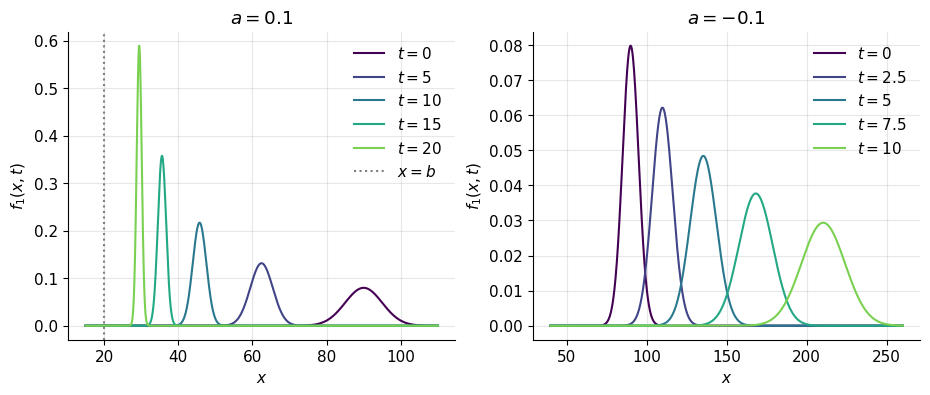

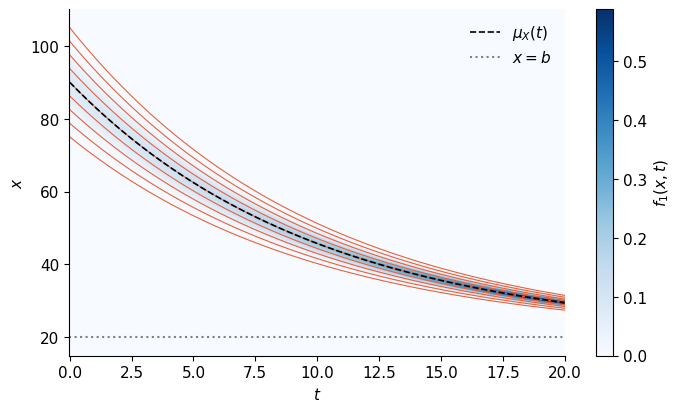

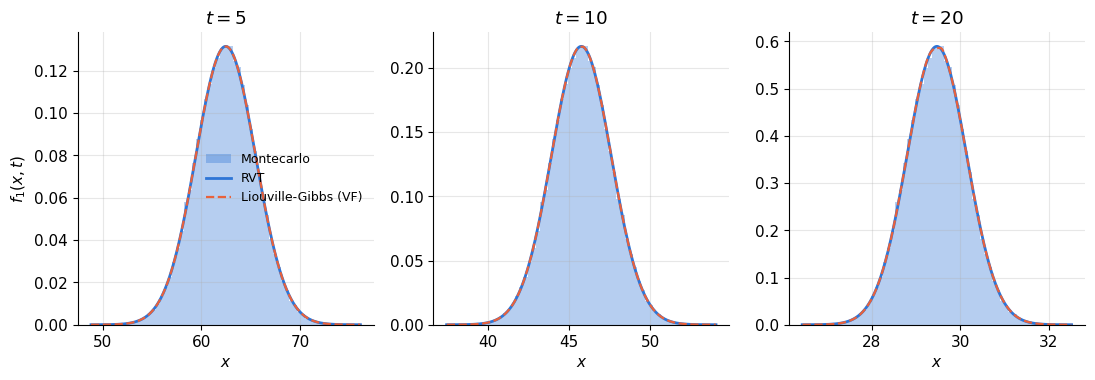

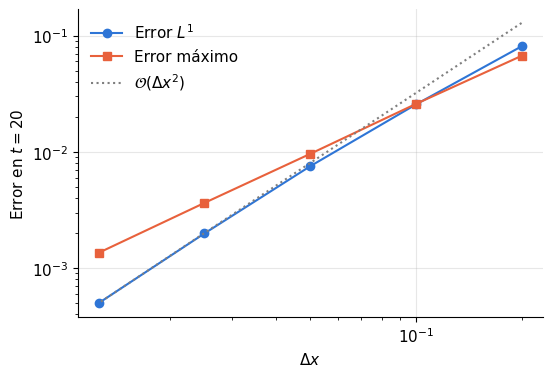

In [7]:
# =====================================================================
# 5) Figuras
# =====================================================================
cmap = plt.cm.viridis

# Figura 1: 1-FDP en varios instantes, a > 0 y a < 0
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
xg = np.linspace(15, 110, 2000)
for k, t in enumerate(TIEMPOS):
    ax[0].plot(xg, f1_rvt(xg, t), color=cmap(k / len(TIEMPOS)), label=f"$t = {t}$")
ax[0].axvline(b, color=GRIS, ls=":", label="$x = b$")
ax[0].set(title=f"$a = {a}$", xlabel="$x$", ylabel="$f_1(x,t)$")
ax[0].legend()
a_neg = -0.1
xg2 = np.linspace(40, 260, 2000)
for k, t in enumerate([0, 2.5, 5, 7.5, 10]):
    ax[1].plot(xg2, f1_rvt(xg2, t, a=a_neg), color=cmap(k / 5), label=f"$t = {t}$")
ax[1].set(title=f"$a = {a_neg}$", xlabel="$x$", ylabel="$f_1(x,t)$")
ax[1].legend()
plt.savefig("fig1_densidades.png"); plt.show()

# Figura 2: mapa de f1(x,t) con curvas características
tg = np.linspace(0, T, 400)
xg = np.linspace(15, 110, 600)
TT, XX = np.meshgrid(tg, xg)
fig, ax = plt.subplots(figsize=(8, 4.5))
cs = ax.pcolormesh(TT, XX, f1_rvt(XX, TT), cmap="Blues", shading="auto")
for xi in np.linspace(mu0 - 3 * s0, mu0 + 3 * s0, 9):
    ax.plot(tg, b + (xi - b) * np.exp(-a * tg), color=NARANJA, lw=0.8)
ax.plot(tg, media_ex(tg), color="k", ls="--", lw=1.2, label=r"$\mu_X(t)$")
ax.axhline(b, color=GRIS, ls=":", label="$x = b$")
ax.set(xlabel="$t$", ylabel="$x$")
ax.grid(False); ax.legend(loc="upper right")
plt.colorbar(cs, ax=ax, label="$f_1(x,t)$")
plt.savefig("fig2_mapa_caracteristicas.png"); plt.show()

# Figura 3: RVT vs Liouville-Gibbs (VF) vs histograma Montecarlo
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
xc5, f_fv5 = liouville_fv(0.025, 5.0)
xc10, f_fv10 = liouville_fv(0.025, 10.0)
for axi, t, (xc_, f_) in zip(ax, [5, 10, 20],
                             [(xc5, f_fv5), (xc10, f_fv10), (xc_fv, f_fv_plot)]):
    m, s = media_ex(t), np.sqrt(var_ex(t))
    xx = np.linspace(m - 4.5 * s, m + 4.5 * s, 600)
    axi.hist(muestras[t], bins=60, density=True, color=AZUL, alpha=0.35,
             label="Montecarlo")
    axi.plot(xx, f1_rvt(xx, t), color=AZUL, lw=2, label="RVT")
    msk = (xc_ > xx[0]) & (xc_ < xx[-1])
    axi.plot(xc_[msk], f_[msk], color=NARANJA, ls="--", lw=1.6,
             label="Liouville-Gibbs (VF)")
    axi.set(title=f"$t = {t}$", xlabel="$x$")
ax[0].set_ylabel("$f_1(x,t)$"); ax[0].legend(fontsize=9)
plt.savefig("fig3_comparacion.png"); plt.show()

# Figura 4: convergencia del esquema de volúmenes finitos
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(dxs, err_L1, "o-", color=AZUL, label="Error $L^1$")
ax.loglog(dxs, err_inf, "s-", color=NARANJA, label="Error máximo")
ax.loglog(dxs, err_L1[-1] * (np.array(dxs) / dxs[-1])**2, ":", color=GRIS,
          label=r"$\mathcal{O}(\Delta x^2)$")
ax.set(xlabel=r"$\Delta x$", ylabel=f"Error en $t = {T:g}$")
ax.legend()
plt.savefig("fig4_convergencia_vf.png"); plt.show()